# 04 — ML Model: Feature Engineering & Target Variable (GBP/IDR)

Builds the feature set (lagged returns, rolling volatility, RSI, MACD, plus the
Week 2 percentile rank / z-score) and the target variable (does the rate rise
over the next N days). Model training comes after this — this notebook stops
right after the target is built and sanity-checked, since that's the part most
worth slowing down for.


In [1]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier


from src.data import get_data_incremental
from src.signals import add_percentile_rank, add_zscore, classify_signal
from src.features import lagged_returns, rolling_volatility, rsi, macd

plt.rcParams["figure.figsize"] = (12, 5)


## 1. Load data + rebuild the Week 2 signal columns

In [2]:
PERIOD = 180

df = get_data_incremental()
df = add_percentile_rank(df, period=PERIOD)
df = add_zscore(df, period=PERIOD)
df["Value_Signal"] = df["Percentile_Rank"].apply(classify_signal)

print(df.shape)
df.tail()


Cache found, last date: 2026-09-14. Checking for new data...


[*********************100%***********************]  1 of 1 completed

Added 1 rows (updated cache total: 3046 rows).
(3046, 7)


,Close,High,Low,Open,Percentile_Rank,Zscore,Value_Signal
Date,,,,,,,
2026-09-08,23927.988281,23930.628906,23799.232422,23923.867188,0.711111,0.871743,Neutral
2026-09-09,23818.583984,23845.804688,23626.261719,23821.517578,0.650000,0.691087,Neutral
2026-09-10,23712.966797,23798.820312,23695.224609,23710.267578,0.572222,0.516448,Neutral
2026-09-11,23764.101562,23822.300781,23677.873047,23763.941406,0.611111,0.588932,Neutral
2026-09-14,23731.470703,23759.359375,23719.210938,23744.500000,0.583333,0.528624,Neutral


## 2. Add features

Lagged returns at three horizons, rolling volatility at two windows, RSI, and MACD.
`Percentile_Rank` and `Zscore` from Week 2 are also used as model features here,
not just as display labels.

In [3]:
df["ret_1d"] = lagged_returns(df, 1)
df["ret_5d"] = lagged_returns(df, 5)
df["ret_20d"] = lagged_returns(df, 20)

df["vol_5d"] = rolling_volatility(df, 5)
df["vol_20d"] = rolling_volatility(df, 20)

df["rsi_14"] = rsi(df, period=14)

macd_df = macd(df)
df["macd"] = macd_df["MACD"]
df["macd_signal"] = macd_df["Signal"]

feature_cols = [
    "ret_1d", "ret_5d", "ret_20d",
    "vol_5d", "vol_20d",
    "rsi_14", "macd", "macd_signal",
    "Percentile_Rank", "Zscore",
]

df[feature_cols].tail()


,ret_1d,ret_5d,ret_20d,vol_5d,vol_20d,rsi_14,macd,macd_signal,Percentile_Rank,Zscore
Date,,,,,,,,,,
2026-09-08,0.003421,-0.001586,-0.004670,0.002460,0.002874,42.517807,-52.009014,-20.779475,0.711111,0.871743
2026-09-09,-0.004572,-0.004105,-0.010677,0.003084,0.003001,24.255333,-60.685318,-28.760643,0.650000,0.691087
2026-09-10,-0.004434,-0.007562,-0.015931,0.003489,0.003103,20.716121,-75.216724,-38.051860,0.572222,0.516448
2026-09-11,0.002156,-0.002725,-0.013876,0.003741,0.003168,28.953721,-81.665431,-46.774574,0.611111,0.588932
2026-09-14,-0.001373,-0.004820,-0.017533,0.003681,0.003088,22.460923,-88.390209,-55.097701,0.583333,0.528624


**Sanity check:** every feature should show `NaN` only during its own warm-up
period, and be a real number after that. Quick scan before moving on.

In [4]:
df[feature_cols].isna().sum()


ret_1d               1
ret_5d               5
ret_20d             20
vol_5d               5
vol_20d             20
rsi_14              60
macd                 0
macd_signal          0
Percentile_Rank    179
Zscore             179
dtype: int64

## 3. Create the target variable

**This is the step most worth being careful with.** The target legitimately looks
*forward* in time (`Close.shift(-HORIZON)`) — that's what makes it a label at all,
not a bug. The lookahead rule only applies to *features*: none of the columns
above use a negative shift, and none of them should ever be allowed to.

Target definition: does `Close` HORIZON trading days from now end up higher than
`Close` today?

In [5]:
HORIZON = 10  # trading days ahead — adjust and re-run to compare later if you want

df["future_close"] = df["Close"].shift(-HORIZON)
df["target"] = (df["future_close"] > df["Close"]).astype(int)

# the last HORIZON rows have no real future value to compare against — the shift
# pulled in NaN for those, so future_close/target for them are meaningless
print("Rows with no valid target (expect exactly HORIZON):", df["future_close"].isna().sum())
df[["Close", "future_close", "target"]].tail(HORIZON + 3)


Rows with no valid target (expect exactly HORIZON): 10


,Close,future_close,target
Date,,,
2026-08-27,24171.804688,23712.966797,0
2026-08-28,24132.703125,23764.101562,0
2026-08-31,24015.156250,23731.470703,0
2026-09-01,23965.994141,NaN,0
2026-09-02,23916.751953,NaN,0
2026-09-03,23893.656250,NaN,0
2026-09-04,23829.039062,NaN,0
2026-09-07,23846.414062,NaN,0
2026-09-08,23927.988281,NaN,0


## 4. Manual spot-check — don't just trust the code ran

Pick a handful of rows well before the end of the dataset and verify by eye that
`target` matches what a human would conclude by comparing `Close` to `future_close`.

In [6]:
check_rows = df.iloc[500:505][["Close", "future_close", "target"]]
print(check_rows)
print()
for date, row in check_rows.iterrows():
    expected = int(row["future_close"] > row["Close"])
    print(f"{date.date()}: Close={row['Close']:.2f}  future_close={row['future_close']:.2f}  "
          f"target={int(row['target'])}  manual_expected={expected}  match={row['target']==expected}")


              Close  future_close  target
Date                                     
2016-12-01  16986.0       16609.0       0
2016-12-02  16720.0       16360.0       0
2016-12-05  16970.0       16449.0       0
2016-12-06  16732.0       16563.0       0
2016-12-07  16713.0       16594.0       0

2016-12-01: Close=16986.00  future_close=16609.00  target=0  manual_expected=0  match=True
2016-12-02: Close=16720.00  future_close=16360.00  target=0  manual_expected=0  match=True
2016-12-05: Close=16970.00  future_close=16449.00  target=0  manual_expected=0  match=True
2016-12-06: Close=16732.00  future_close=16563.00  target=0  manual_expected=0  match=True
2016-12-07: Close=16713.00  future_close=16594.00  target=0  manual_expected=0  match=True


## 5. Check the target's class balance

Important context before evaluating any model later: if this is heavily skewed
toward one class, the naive baseline accuracy will already be high, and a model
needs to clear *that*, not 50%.

In [7]:
print(df["target"].value_counts(dropna=False))
print()
print("Proportion positive (rate goes up):", df["target"].mean())


target
1    1582
0    1464
Name: count, dtype: int64

Proportion positive (rate goes up): 0.5193696651346028


## 6. Drop rows that can't be used

- The warm-up period at the start (features not fully formed yet)
- The last `HORIZON` rows at the end (no valid target)

In [8]:
model_df = df.dropna(subset=feature_cols + ["target"]).copy()
print(f"Original rows: {len(df)}  ->  usable rows: {len(model_df)}")
print("Date range:", model_df.index.min().date(), "to", model_df.index.max().date())


Original rows: 3046  ->  usable rows: 2820
Date range: 2015-09-09 to 2026-09-14


## Next steps

- Chronological train/test split on `model_df` (no shuffling)
- Naive majority-class baseline on the test set
- Train logistic regression and XGBoost classifiers
- Evaluate against the baseline, check feature importances
- Write an honest conclusion — given Week 3's Option C result was close to
  a zero real-world edge, a modest improvement here would be a genuinely
  good outcome, not a disappointing one.


In [9]:
# --- Chronological split WITH a purge gap ---
# The target is Close.shift(-HORIZON), so a training row this close to the
# boundary has a label that depends on Close prices inside what would be the
# test window. Drop HORIZON rows between train and test so no label crosses
# the boundary in either direction.

n = len(model_df)
test_frac = 0.2
n_test = int(n * test_frac)
n_train_end = n - n_test - HORIZON  # leave room for the purge gap

train_df = model_df.iloc[:n_train_end]
test_df = model_df.iloc[n_train_end + HORIZON:]  # same test set as before

X_train = train_df.drop(columns=["target", "future_close", "Value_Signal"])
y_train = train_df["target"]
X_test = test_df.drop(columns=["target", "future_close", "Value_Signal"])
y_test = test_df["target"]

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train dates:", X_train.index.min().date(), "to", X_train.index.max().date())
print(f"Purge gap: {HORIZON} rows dropped between train and test (not used by either)")
print("Test dates: ", X_test.index.min().date(), "to", X_test.index.max().date())

# Naive baseline: always predict the majority class in the test set
naive_baseline = max(y_test.mean(), 1 - y_test.mean())
print(f"\nNaive majority-class baseline accuracy: {naive_baseline:.4f}")
print()


# 1. Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

log_reg = LogisticRegression(random_state=42, max_iter=1000)
log_reg.fit(X_train_scaled, y_train)
y_pred_lr = log_reg.predict(X_test_scaled)

acc_lr = accuracy_score(y_test, y_pred_lr)
print(f"Logistic Regression Accuracy: {acc_lr:.4f}  (baseline: {naive_baseline:.4f}, "
      f"edge: {acc_lr - naive_baseline:+.4f})")
print(classification_report(y_test, y_pred_lr))

# 2. XGBoost — constrained + early-stopped
# Default XGBoost previously scored *below* the naive baseline on the test set,
# which is an overfitting signature, not evidence the model can't work here.
# Fix: cap depth, add subsample/colsample + L1/L2 regularization, and pick the
# number of trees via early stopping on a validation slice carved out of the
# training period (its own purge gap too) -- the test set is never used to
# choose the model.
val_frac = 0.15
n_val = int(len(train_df) * val_frac)
n_fit_end = len(train_df) - n_val - HORIZON  # purge gap before the val slice too

fit_df = train_df.iloc[:n_fit_end]
val_df = train_df.iloc[n_fit_end + HORIZON:]

X_fit = fit_df.drop(columns=["target", "future_close", "Value_Signal"])
y_fit = fit_df["target"]
X_val = val_df.drop(columns=["target", "future_close", "Value_Signal"])
y_val = val_df["target"]

xgb_clf = XGBClassifier(
    random_state=42,
    eval_metric="logloss",
    n_estimators=500,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=1.0,
    reg_lambda=1.0,
    early_stopping_rounds=30,
)
xgb_clf.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], verbose=False)
print(f"XGBoost stopped at iteration {xgb_clf.best_iteration} "
      f"(cap was {xgb_clf.n_estimators})")

y_pred_xgb = xgb_clf.predict(X_test)

acc_xgb = accuracy_score(y_test, y_pred_xgb)
print(f"XGBoost Accuracy: {acc_xgb:.4f}  (baseline: {naive_baseline:.4f}, "
      f"edge: {acc_xgb - naive_baseline:+.4f})")
print(classification_report(y_test, y_pred_xgb))


Train: (2246, 14) Test: (564, 14)
Train dates: 2015-09-09 to 2024-06-25
Purge gap: 10 rows dropped between train and test (not used by either)
Test dates:  2024-07-10 to 2026-09-14

Naive majority-class baseline accuracy: 0.5851

Logistic Regression Accuracy: 0.4291  (baseline: 0.5851, edge: -0.1560)
              precision    recall  f1-score   support

           0       0.42      1.00      0.59       234
           1       0.90      0.03      0.05       330

    accuracy                           0.43       564
   macro avg       0.66      0.51      0.32       564
weighted avg       0.70      0.43      0.28       564

XGBoost stopped at iteration 0 (cap was 500)
XGBoost Accuracy: 0.4149  (baseline: 0.5851, edge: -0.1702)
              precision    recall  f1-score   support

           0       0.41      1.00      0.59       234
           1       0.00      0.00      0.00       330

    accuracy                           0.41       564
   macro avg       0.21      0.50      0.29     

/Users/jasonsetyadi/Desktop/forex-gb-idr/venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/jasonsetyadi/Desktop/forex-gb-idr/venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/jasonsetyadi/Desktop/forex-gb-idr/venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p

## 7. Walk-forward evaluation across multiple windows

The single split above is one data point — and it turned out to be a noisy one:
shifting the boundary by just the `HORIZON`-row purge gap flipped the
Logistic Regression "edge" from +0.002 to -0.156. That's a sign the class
balance isn't stationary over time (checked below), not that either number is
reliable on its own.

To find out if there's *any* consistent edge, walk the same train → purge gap
→ test procedure forward across several non-overlapping windows (an expanding
training window each time, like real deployment would work), and look at the
spread of results instead of a single number.

In [10]:
N_FOLDS = 5

n = len(model_df)
block_size = n // (N_FOLDS + 1)  # fold 0 is the initial training-only block

fold_results = []

for fold in range(1, N_FOLDS + 1):
    train_end = fold * block_size
    test_start = train_end
    test_end = test_start + block_size if fold < N_FOLDS else n  # last fold takes the remainder

    train_df_f = model_df.iloc[: train_end - HORIZON]        # purge gap before test
    test_df_f = model_df.iloc[test_start:test_end]

    X_train_f = train_df_f.drop(columns=["target", "future_close", "Value_Signal"])
    y_train_f = train_df_f["target"]
    X_test_f = test_df_f.drop(columns=["target", "future_close", "Value_Signal"])
    y_test_f = test_df_f["target"]

    baseline = max(y_test_f.mean(), 1 - y_test_f.mean())

    # Logistic Regression
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_f)
    X_test_scaled = scaler.transform(X_test_f)
    lr = LogisticRegression(random_state=42, max_iter=1000)
    lr.fit(X_train_scaled, y_train_f)
    acc_lr = accuracy_score(y_test_f, lr.predict(X_test_scaled))

    # XGBoost, early-stopped on a purged validation slice carved out of this fold's training data
    val_frac = 0.15
    n_val = int(len(train_df_f) * val_frac)
    n_fit_end = len(train_df_f) - n_val - HORIZON
    fit_df_f = train_df_f.iloc[:n_fit_end]
    val_df_f = train_df_f.iloc[n_fit_end + HORIZON:]

    X_fit_f = fit_df_f.drop(columns=["target", "future_close", "Value_Signal"])
    y_fit_f = fit_df_f["target"]
    X_val_f = val_df_f.drop(columns=["target", "future_close", "Value_Signal"])
    y_val_f = val_df_f["target"]

    xgb_f = XGBClassifier(
        random_state=42,
        eval_metric="logloss",
        n_estimators=500,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=1.0,
        reg_lambda=1.0,
        early_stopping_rounds=30,
    )
    xgb_f.fit(X_fit_f, y_fit_f, eval_set=[(X_val_f, y_val_f)], verbose=False)
    acc_xgb = accuracy_score(y_test_f, xgb_f.predict(X_test_f))

    fold_results.append({
        "fold": fold,
        "train_start": X_train_f.index.min().date(),
        "train_end": X_train_f.index.max().date(),
        "test_start": X_test_f.index.min().date(),
        "test_end": X_test_f.index.max().date(),
        "n_train": len(X_train_f),
        "n_test": len(X_test_f),
        "train_y_mean": y_train_f.mean(),
        "test_y_mean": y_test_f.mean(),
        "baseline": baseline,
        "lr_acc": acc_lr,
        "lr_edge": acc_lr - baseline,
        "xgb_acc": acc_xgb,
        "xgb_edge": acc_xgb - baseline,
        "xgb_best_iter": xgb_f.best_iteration,
    })

fold_df = pd.DataFrame(fold_results)
pd.set_option("display.width", 140)
print(fold_df.drop(columns=["train_start"]).to_string(index=False))

print()
print(f"Logistic Regression edge across folds: mean={fold_df['lr_edge'].mean():+.4f}  "
      f"std={fold_df['lr_edge'].std():.4f}  folds beating baseline={(fold_df['lr_edge'] > 0).sum()}/{N_FOLDS}")
print(f"XGBoost edge across folds:            mean={fold_df['xgb_edge'].mean():+.4f}  "
      f"std={fold_df['xgb_edge'].std():.4f}  folds beating baseline={(fold_df['xgb_edge'] > 0).sum()}/{N_FOLDS}")


 fold  train_end test_start   test_end  n_train  n_test  train_y_mean  test_y_mean  baseline   lr_acc   lr_edge  xgb_acc  xgb_edge  xgb_best_iter
    1 2017-06-13 2017-06-28 2019-04-18      460     470      0.445652     0.557447  0.557447 0.493617 -0.063830 0.442553 -0.114894              0
    2 2019-04-04 2019-04-19 2021-04-12      930     470      0.510753     0.502128  0.502128 0.463830 -0.038298 0.538298  0.036170             10
    3 2021-03-29 2021-04-13 2023-01-30     1400     470      0.503571     0.410638  0.589362 0.574468 -0.014894 0.508511 -0.080851              3
    4 2023-01-16 2023-01-31 2024-11-18     1870     470      0.483957     0.578723  0.578723 0.478723 -0.100000 0.421277 -0.157447              0
    5 2024-11-04 2024-11-19 2026-09-14     2340     470      0.502991     0.619149  0.619149 0.400000 -0.219149 0.380851 -0.238298              0

Logistic Regression edge across folds: mean=-0.0872  std=0.0802  folds beating baseline=0/5
XGBoost edge across folds:     

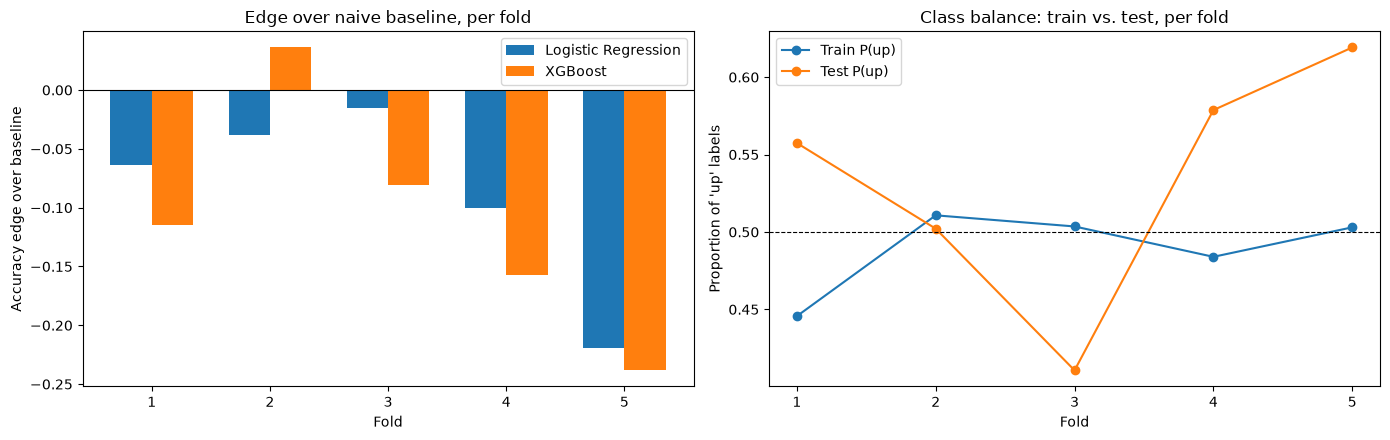

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

x = fold_df["fold"]
width = 0.35
axes[0].bar(x - width/2, fold_df["lr_edge"], width, label="Logistic Regression")
axes[0].bar(x + width/2, fold_df["xgb_edge"], width, label="XGBoost")
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_xlabel("Fold")
axes[0].set_ylabel("Accuracy edge over baseline")
axes[0].set_title("Edge over naive baseline, per fold")
axes[0].set_xticks(x)
axes[0].legend()

axes[1].plot(x, fold_df["train_y_mean"], marker="o", label="Train P(up)")
axes[1].plot(x, fold_df["test_y_mean"], marker="o", label="Test P(up)")
axes[1].axhline(0.5, color="black", linewidth=0.8, linestyle="--")
axes[1].set_xlabel("Fold")
axes[1].set_ylabel("Proportion of 'up' labels")
axes[1].set_title("Class balance: train vs. test, per fold")
axes[1].set_xticks(x)
axes[1].legend()

plt.tight_layout()
plt.show()

## 8. Conclusion

**Neither model shows a real edge, and the walk-forward result — not the first
single split — is the one to trust.**

- Logistic Regression beat the naive majority-class baseline in **0 of 5**
  walk-forward folds (mean edge **-0.087**).
- XGBoost beat it in **1 of 5** folds, barely (mean edge **-0.111**).
- The very first single 80/20 split (before the purge gap) happened to show a
  tiny positive edge for Logistic Regression (+0.002). That was luck of where
  the boundary fell, not a real result: moving the boundary by just the
  10-day purge gap flipped it to -0.156, and the 5-fold walk-forward confirms
  the honest picture is negative, consistently, across 2017-2026.
- The deeper reason is visible in the fold table: the target's class balance
  ("proportion of 'up' periods") swings from 0.50 to 0.62 across folds — GBP/IDR
  alternates between roughly balanced, mean-reverting stretches and sustained
  IDR-depreciation trends. A model trained once on pooled history picks up
  mean-reversion-flavored patterns (from RSI/Zscore/Percentile-Rank) that work
  in the balanced stretches and actively hurt it during trending ones — which
  is exactly why both models lose to a trivial majority-class guess more often
  than not.

This is consistent with Week 3's finding that the rule-based signal was close
to a zero real-world edge: **the current price-only feature set (lagged
returns, volatility, RSI, MACD, percentile rank, z-score) does not contain a
usable predictive signal for the 10-day-ahead direction of GBP/IDR**, at least
not one either model can exploit reliably out of sample. Tuning
hyperparameters further or trying other price-only model architectures is
unlikely to fix this — the ceiling here looks like it's set by the feature
set and the regime-dependent target, not by model choice.

**Next avenue worth trying, if pursued:** features that aren't derived purely
from GBP/IDR's own price history — e.g. USD/IDR and GBP/USD (GBP/IDR is
technically a cross rate of the two) and an interest-rate-differential proxy
for the IDR carry trade, which is a more plausible driver of medium-horizon EM
FX moves than technical indicators on the cross rate alone.